# Canadian labour market: unemployment trends

Source: Statistics Canada table 14-10-0287-01 (monthly, seasonally adjusted). Run all cells; charts go to `outputs/` and the table behind them to `analysis_ready/`.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import logging
import re
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
pd.options.display.max_colwidth = 90
pd.options.display.float_format = "{:,.2f}".format


def find_hub_root():
    """Walk up from this notebook's folder until we find the hub (it contains processed/statcan)."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "processed" / "statcan").exists():
            return folder
    raise FileNotFoundError(
        "Could not find the hub folder (a folder that contains processed/statcan). "
        "Open this notebook from inside the repository and run the download script first."
    )


HUB = find_hub_root()
OUTPUTS = HUB / "outputs"                # charts are saved here
ANALYSIS_READY = HUB / "analysis_ready"  # summary tables are saved here
OUTPUTS.mkdir(exist_ok=True)
ANALYSIS_READY.mkdir(exist_ok=True)


# Chart style: light surface, thin lines, quiet grid. Colours are used in a fixed order
# (blue, orange, aqua, ...) so a series keeps the same colour in every chart. Gray is for context.
SURFACE, INK, INK2 = "#fcfcfb", "#0b0b0b", "#52514e"
GRID, AXIS, MUTED = "#e1e0d9", "#c3c2b7", "#898781"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#e34948"
)
SERIES_COLOURS = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "figure.dpi": 110,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "legend.frameon": False,
})


def subtitle(ax, text):
    """Small grey line under the chart title (we use it to show exactly which series is plotted)."""
    ax.text(0, 1.02, text, transform=ax.transAxes, fontsize=9.5, color=INK2, va="bottom", ha="left")


def spread(values, min_gap):
    """Nudge label positions apart so direct labels do not overlap."""
    values = np.asarray(values, dtype=float)
    order = np.argsort(values)
    pos = values[order].copy()
    for i in range(1, len(pos)):
        if pos[i] - pos[i - 1] < min_gap:
            pos[i] = pos[i - 1] + min_gap
    out = np.empty_like(pos)
    out[order] = pos
    return out


def direct_labels(ax, items):
    """Label each line at its right-hand end. items = [(text, series), ...]"""
    low, high = ax.get_ylim()
    ys = spread([s.iloc[-1] for _, s in items], 0.06 * (high - low))
    for (text, s), y in zip(items, ys):
        ax.annotate(text, (s.index[-1], y), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color=INK2)


def save_fig(fig, name):
    path = OUTPUTS / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved chart:", path.relative_to(HUB))


def clean_unit(text):
    """'Persons in thousands, thousands' -> 'Persons in thousands' (drop a repeated scale word)."""
    kept = []
    for part in [p.strip() for p in str(text).split(",")]:
        if part and not any(part.lower() in k.lower() for k in kept):
            kept.append(part)
    return ", ".join(kept)


def load_table(table_number):
    """Read the processed file for a Statistics Canada table, e.g. '14-10-0287-01'."""
    pid = re.sub(r"\D", "", table_number)[:8]
    matches = sorted((HUB / "processed" / "statcan").glob(f"statcan_{pid}_*/statcan_{pid}_*.csv"))
    if not matches:
        raise FileNotFoundError(f"No processed file for table {table_number}. Run the download script first.")
    if len(matches) > 1:
        print("Several files found, using the first:", [m.name for m in matches])
    frame = pd.read_csv(
        matches[0], dtype={"geography": str, "series": str, "unit": str, "status": str},
        na_values=[""], keep_default_na=False,
    )
    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")
    frame["value"] = pd.to_numeric(frame["value"], errors="coerce")
    return frame, matches[0]


df, _ = load_table("14-10-0287-01")

def parts_of(label):
    """'Unemployment rate | Total - Gender | ...' -> ['unemployment rate', 'total - gender', ...]"""
    return [p.strip().lower() for p in label.split("|")]


all_parts = sorted({p for label in df["series"].unique() for p in parts_of(label)})
if len(all_parts) > 150:
    print(f"  ... and {len(all_parts) - 150} more")

# Names to look for. Each entry is a list of acceptable spellings (lower case).
NAMES = {
    "unemployment_rate": ["unemployment rate"],
    "employment": ["employment"],
    "participation_rate": ["participation rate"],
    "employment_rate": ["employment rate"],
    "total_gender": ["total - gender", "both sexes", "total"],
    "men": ["men+", "men", "males"],
    "women": ["women+", "women", "females"],
    "all_ages": ["15 years and over"],
    "youth": ["15 to 24 years"],
    "core": ["25 to 54 years"],
    "older": ["55 years and over"],
    "seasonally_adjusted": ["seasonally adjusted"],
    "estimate": ["estimate"],
}
# For the headline charts we want: seasonally adjusted, both genders, all ages.
HEADLINE = ("seasonally_adjusted", "total_gender", "all_ages", "estimate")

GEO = "Canada" if "Canada" in set(df["geography"]) else sorted(df["geography"].unique())[0]
data = df[df["geography"] == GEO]
labels_all = data["series"].unique()


def _matches(hard, soft, avoid):
    def has(parts, key):
        return any(p in NAMES[key] for p in parts)

    return [
        label for label in labels_all
        if all(has(parts_of(label), k) for k in (*hard, *soft))
        and not any(has(parts_of(label), k) for k in avoid)
    ]


def pick(*hard, soft=(), avoid=()):
    """Find ONE series. `hard` names must match. `soft` names are used if they exist and
    dropped, last first, if nothing matches. Returns (values by date, label, unit)."""
    for keep in range(len(soft), -1, -1):
        labels = _matches(hard, soft[:keep], avoid)
        if labels:
            break
    else:
        raise LookupError(f"No series matched {hard}. Look at the list of names above and edit NAMES.")
    if keep < len(soft):
        print(f"Note: could not match {soft[keep:]} for {hard}; used a broader match.")
    if len(labels) > 1:
        print(f"Note: {len(labels)} series matched {hard}; using the first. Others include: {labels[1:3]}")
    label = labels[0]
    rows = data[data["series"] == label].dropna(subset=["date", "value"])
    values = rows.drop_duplicates("date").sort_values("date").set_index("date")["value"]
    units = data.loc[data["series"] == label, "unit"].dropna()
    unit = clean_unit(units.mode().iloc[0]) if len(units) else ""
    return values, label, unit

unemp, unemp_label, unemp_unit = pick("unemployment_rate", soft=HEADLINE)

Saved chart: outputs\lfs_unemployment_rate.png


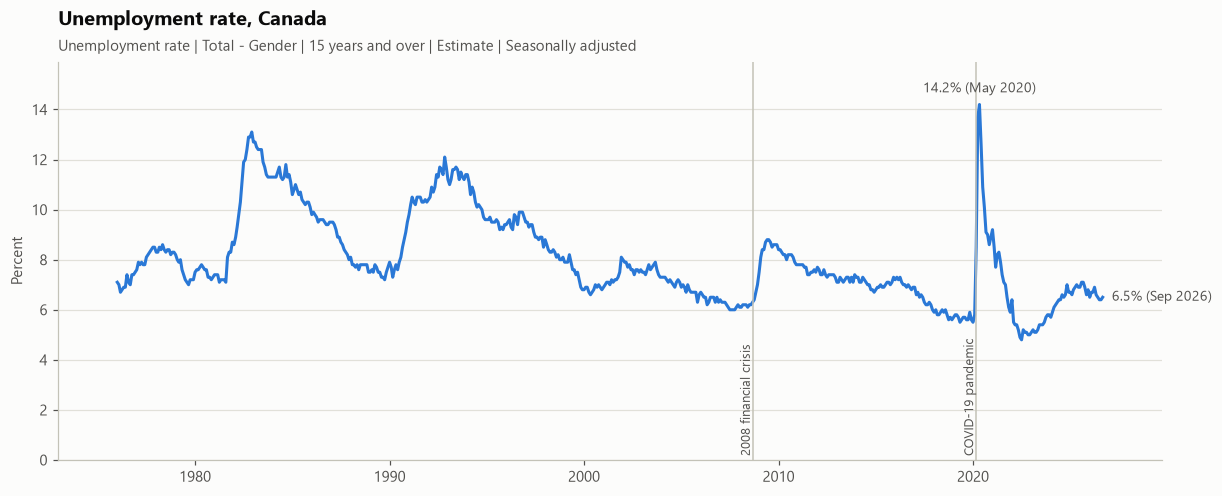

### Findings
- **Now:** unemployment is **6.5%** (September 2026), 0.6 points lower than a year earlier.
- **Range since 2000:** low of 4.8% (Jul 2022), high of 14.2% (May 2020).
- **Distance from the low:** the current rate is 1.7 points above the post-2000 low.
- **Versus pre-pandemic:** the rate was 5.8% in Feb 2020; it is now +0.7 points from that level.

In [2]:
EVENTS = [("2008-09-01", "2008 financial crisis"), ("2020-03-01", "COVID-19 pandemic")]


def mark_events(ax):
    """Thin vertical lines for the events above (only those inside the chart's date range)."""
    low, high = ax.get_xlim()
    bottom = ax.get_ylim()[0]
    for when, name in EVENTS:
        x = mdates.date2num(pd.Timestamp(when))
        if low <= x <= high:
            ax.axvline(x, color=AXIS, lw=1)
            ax.text(x, bottom, " " + name, rotation=90, ha="right", va="bottom", fontsize=8.5, color=INK2)


fig, ax = plt.subplots(figsize=(11, 4.4), constrained_layout=True)
ax.plot(unemp.index, unemp.values, color=BLUE)
ax.set_ylim(0, max(unemp.max() * 1.12, 1))
ax.margins(x=0.06)
ax.set_ylabel("Percent")
ax.set_title("Unemployment rate, Canada", pad=24)
subtitle(ax, unemp_label)

recent = unemp[unemp.index >= "1996-01-01"]
ax.annotate(f"{unemp.iloc[-1]:.1f}% ({unemp.index[-1]:%b %Y})", (unemp.index[-1], unemp.iloc[-1]),
            xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
ax.annotate(f"{recent.max():.1f}% ({recent.idxmax():%b %Y})", (recent.idxmax(), recent.max()),
            xytext=(0, 6), textcoords="offset points", ha="center", va="bottom", fontsize=9, color=INK2)
mark_events(ax)
save_fig(fig, "lfs_unemployment_rate")
plt.show()

since2000 = unemp[unemp.index >= "2000-01-01"]
pre = unemp[unemp.index < "2020-03-01"]
yr_ago = unemp[unemp.index <= unemp.index[-1] - pd.DateOffset(years=1)].iloc[-1]
low = since2000.idxmin()
lines = [
    f"- **Now:** unemployment is **{unemp.iloc[-1]:.1f}%** ({unemp.index[-1]:%B %Y}), {'unchanged from a year earlier' if abs(unemp.iloc[-1] - yr_ago) < 0.05 else f"{abs(unemp.iloc[-1] - yr_ago):.1f} points {'higher' if unemp.iloc[-1] > yr_ago else 'lower'} than a year earlier"}.",
    f"- **Range since 2000:** low of {since2000.min():.1f}% ({low:%b %Y}), high of {since2000.max():.1f}% ({since2000.idxmax():%b %Y}).",
    f"- **Distance from the low:** the current rate is {unemp.iloc[-1] - since2000.min():.1f} points above the post-2000 low.",
]
if len(pre):
    lines.append(f"- **Versus pre-pandemic:** the rate was {pre.iloc[-1]:.1f}% in {pre.index[-1]:%b %Y}; it is now {unemp.iloc[-1] - pre.iloc[-1]:+.1f} points from that level.")
display(Markdown("### Findings\n" + "\n".join(lines)))


Saved chart: outputs\lfs_unemployment_by_age.png


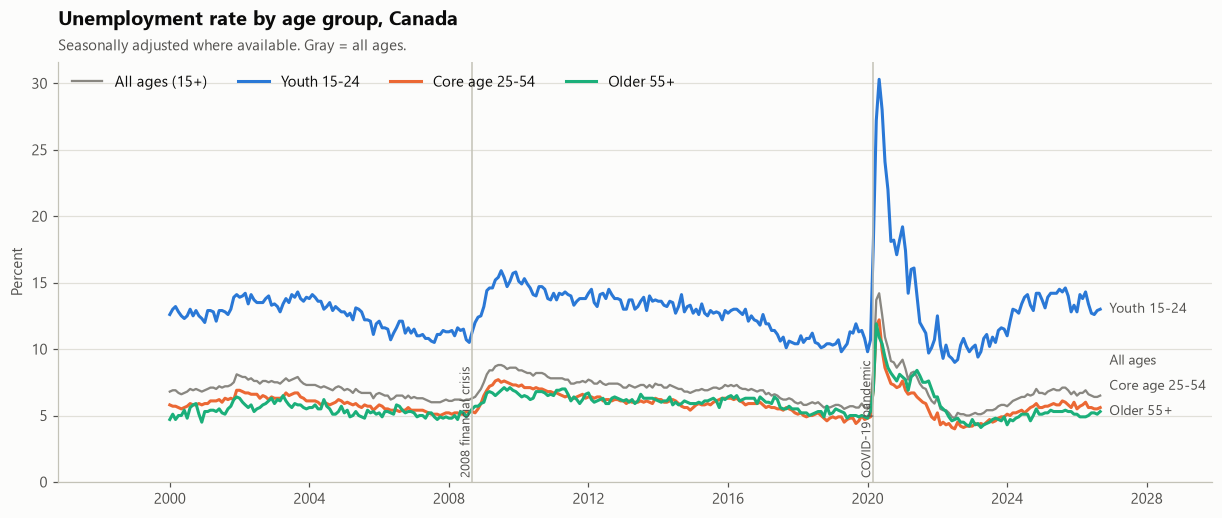

### Findings
- **Youth vs other ages:** the youth rate is **13.0%**, about 2.3x the 25-54 rate (5.6%) and 2.5x the 55+ rate (5.3%).
- **Pandemic shock:** between 2020 and 2021 youth unemployment peaked at 30.3%, versus 12.2% for ages 25-54 and 11.9% for 55+.
- **Gap vs all ages:** the all-ages rate is 6.5%, so the youth gap is +6.5 points.
- **Why it matters for risk:** groups with higher unemployment are more exposed to missed loan payments when the economy weakens.

Saved table: analysis_ready\lfs_unemployment_rate_by_age_monthly.csv


In [3]:
START = "2000-01-01"
SOFT = ("seasonally_adjusted", "total_gender", "estimate")
youth, youth_label, _ = pick("unemployment_rate", "youth", soft=SOFT)
core, core_label, _ = pick("unemployment_rate", "core", soft=SOFT)
older, older_label, _ = pick("unemployment_rate", "older", soft=SOFT)
everyone, _, _ = pick("unemployment_rate", "all_ages", soft=SOFT)

fig, ax = plt.subplots(figsize=(11, 4.6), constrained_layout=True)
ax.plot(everyone.loc[START:].index, everyone.loc[START:].values, color=MUTED, lw=1.5, label="All ages (15+)")
lines = [("Youth 15-24", youth, BLUE), ("Core age 25-54", core, ORANGE), ("Older 55+", older, AQUA)]
for name, s, colour in lines:
    ax.plot(s.loc[START:].index, s.loc[START:].values, color=colour, label=name)
ax.set_ylim(bottom=0)
ax.margins(x=0.12)
ax.set_ylabel("Percent")
ax.set_title("Unemployment rate by age group, Canada", pad=24)
subtitle(ax, "Seasonally adjusted where available. Gray = all ages.")
direct_labels(ax, [(n, s.loc[START:]) for n, s, _ in lines] + [("All ages", everyone.loc[START:])])
ax.legend(loc="upper left", ncols=4)
mark_events(ax)
save_fig(fig, "lfs_unemployment_by_age")
plt.show()

rows = {n: s for n, s, _ in lines}
y, c, o = rows["Youth 15-24"], rows["Core age 25-54"], rows["Older 55+"]
hits = {n: s.loc["2020-02-01":"2021-12-01"].max() for n, s in rows.items()}
display(Markdown("### Findings\n" + "\n".join([
    f"- **Youth vs other ages:** the youth rate is **{y.iloc[-1]:.1f}%**, about {y.iloc[-1] / c.iloc[-1]:.1f}x the 25-54 rate ({c.iloc[-1]:.1f}%) and {y.iloc[-1] / o.iloc[-1]:.1f}x the 55+ rate ({o.iloc[-1]:.1f}%).",
    f"- **Pandemic shock:** between 2020 and 2021 youth unemployment peaked at {hits['Youth 15-24']:.1f}%, versus {hits['Core age 25-54']:.1f}% for ages 25-54 and {hits['Older 55+']:.1f}% for 55+.",
    f"- **Gap vs all ages:** the all-ages rate is {everyone.iloc[-1]:.1f}%, so the youth gap is {y.iloc[-1] - everyone.iloc[-1]:+.1f} points.",
    "- **Why it matters for risk:** groups with higher unemployment are more exposed to missed loan payments when the economy weakens.",
])))

table = pd.DataFrame({"all_ages": everyone, **{n: s for n, s in rows.items()}}).loc[START:]
table.index.name = "date"
table.round(2).to_csv(ANALYSIS_READY / "lfs_unemployment_rate_by_age_monthly.csv")
print("Saved table:", (ANALYSIS_READY / "lfs_unemployment_rate_by_age_monthly.csv").relative_to(HUB))
